 ============================================================

### PROYECTO MARVEL SUPERHEROES

Visión General / Proyecto Power BI - Ingrid

 ============================================================
 
¿Quién es quién en Marvel?

KPIs: total héroes, % héroes vs villanos, % mutantes, % de humanos, Razas
- Donut: distribución Good / Bad / Neutral
- Barras horizontales: top razas (Human, Mutant, Asgardian, Symbiote…)
- Barras apiladas: género × alineación
- Filtro global por alineación y género

Dashboard 2 — Mapa de Poderes
¿Qué puede hacer cada héroe? ¿Quien es mas poderoso? ¿Que poderes predominan?

- barras: los 20 poderes más comunes en Marvel
- Matriz/barras: raza × poder destacado (Mutant + Telepathy, Asgardian + Strength…)
- Tabla interactiva: buscar héroe y ver sus poderes activosbarras: 
- barra: héroe con más poderes por genero
- barras: Poderes mas frecuentes
- KPI's: total de poderes diferentes / promedio de poderes / maximo de poderes por personaje

Dashboard 3 — Héroes vs Villanos
- Las diferencias reales entre buenos y malos
- Barras comparativas: poderes más asociados a héroes vs villanos
- Top 10 héroinas más poderosas (por cantidad de poderes) y top 10 villanas
- Filtro por raza para cruzar con alineación


-  Filtrar Publisher = "Marvel Comics" desde el inicio /contexto Marvel vs DC Comics
-  Merge de las dos tablas por nombre (puede haber discrepancias -revisar)
-  Crear columna calculada Power Count = suma de columnas True/False

Paleta de color: Marvel (#ED1D24), gris oscuro 687782, azul 2980B9, rojo C0392B, mostaza 39C12, verde turquesa 12B99A , morado 9B4DA8, azul indigo 5265A8, (opcional crema FFF1D2) — da consistencia visual inmediata.

Para iniciar: añadir una página de portada con contexto editoriales y terminar con pagina 
de conclusiones.

### DASHBOARD 1

In [ ]:
# ============================================================
# MARVEL SUPERHEROES - DASHBOARD 1: Visión General
# Proyecto Power BI - Ingrid
# ============================================================
#  1 — Importar librerías
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os
import warnings #Esto sirve para manejar las advertencias que puedan surgir durante la ejecución del código
warnings.filterwarnings('ignore')

In [23]:
# ============================================================
# 2 — Carga de datos
# ============================================================
heroes = pd.read_csv("heroes_information.csv")
powers = pd.read_csv("super_hero_powers.csv")
 
print("heroes_information shape:", heroes.shape)
print("super_hero_powers shape:", powers.shape)
heroes.head(3)

heroes_information shape: (734, 11)
super_hero_powers shape: (667, 168)


,Unnamed: 0,name,Gender,Eye color,Race,Hair color,Height,Publisher,Skin color,Alignment,Weight
0,0,A-Bomb,Male,yellow,Human,No Hair,203.0,Marvel Comics,-,good,441.0
1,1,Abe Sapien,Male,blue,Icthyo Sapien,No Hair,191.0,Dark Horse Comics,blue,good,65.0
2,2,Abin Sur,Male,blue,Ungaran,No Hair,185.0,DC Comics,red,good,90.0


In [ ]:
# ============================================================
#  3 — Limpieza y filtrado Marvel
# ============================================================
 
# Filtrar solo Marvel
marvel = heroes[heroes["Publisher"] == "Marvel Comics"].copy()
print(f"Héroes Marvel: {len(marvel)}")
 
# Reemplazar '-' por None en columnas categóricas
for col in ["Gender", "Alignment", "Race", "Eye color", "Hair color", "Skin color"]:
    marvel[col] = marvel[col].replace("-", None)
 
# Reemplazar -99 por None en altura y peso
marvel["Height"] = marvel["Height"].replace(-99.0, None)
marvel["Weight"] = marvel["Weight"].replace(-99.0, None)
 
# Eliminar columna índice sobrante
marvel = marvel.drop(columns=["Unnamed: 0"], errors="ignore")
 
# Reset index
marvel = marvel.reset_index(drop=True)
 
print("\nValores nulos tras limpieza:")
print(marvel.isnull().sum())
print("\nAlineaciones:", marvel["Alignment"].value_counts(dropna=False).to_dict())
print("Géneros:", marvel["Gender"].value_counts(dropna=False).to_dict())

Héroes Marvel: 388

Valores nulos tras limpieza:
name            0
Gender         25
Eye color      51
Race          173
Hair color     52
Height         64
Publisher       0
Skin color    353
Alignment       3
Weight         69
dtype: int64

Alineaciones: {'good': 259, 'bad': 115, 'neutral': 11, nan: 3}
Géneros: {'Male': 252, 'Female': 111, nan: 25}


In [ ]:
# ============================================================
# 4 — Merge con poderes
# ============================================================
 
power_cols = [c for c in powers.columns if c != "hero_names"]
 
# Convertir True/False a 1/0
powers_binary = powers.copy()
powers_binary[power_cols] = powers_binary[power_cols].replace({True: 1, False: 0})
 
# Merge
marvel_full = marvel.merge(
    powers_binary,
    left_on="name",
    right_on="hero_names",
    how="left"
)
 
# Columna: total de poderes por héroe
marvel_full["power_count"] = marvel_full[power_cols].sum(axis=1)
marvel_full["power_count"] = pd.to_numeric(marvel_full["power_count"], errors="coerce")
 
print(f"\nDataset final shape: {marvel_full.shape}")
print(f"Héroes con datos de poderes: {marvel_full['hero_names'].notna().sum()}")
print(f"Héroes SIN datos de poderes: {marvel_full['hero_names'].isna().sum()}")
print(f"\nPoderes promedio por héroe: {marvel_full['power_count'].mean():.1f}")
print(f"Héroe con más poderes: {marvel_full.loc[marvel_full['power_count'].idxmax(), 'name']} ({marvel_full['power_count'].max()} poderes)")
 


Dataset final shape: (388, 179)
Héroes con datos de poderes: 341
Héroes SIN datos de poderes: 47

Poderes promedio por héroe: 7.9
Héroe con más poderes: Living Tribunal (35 poderes)


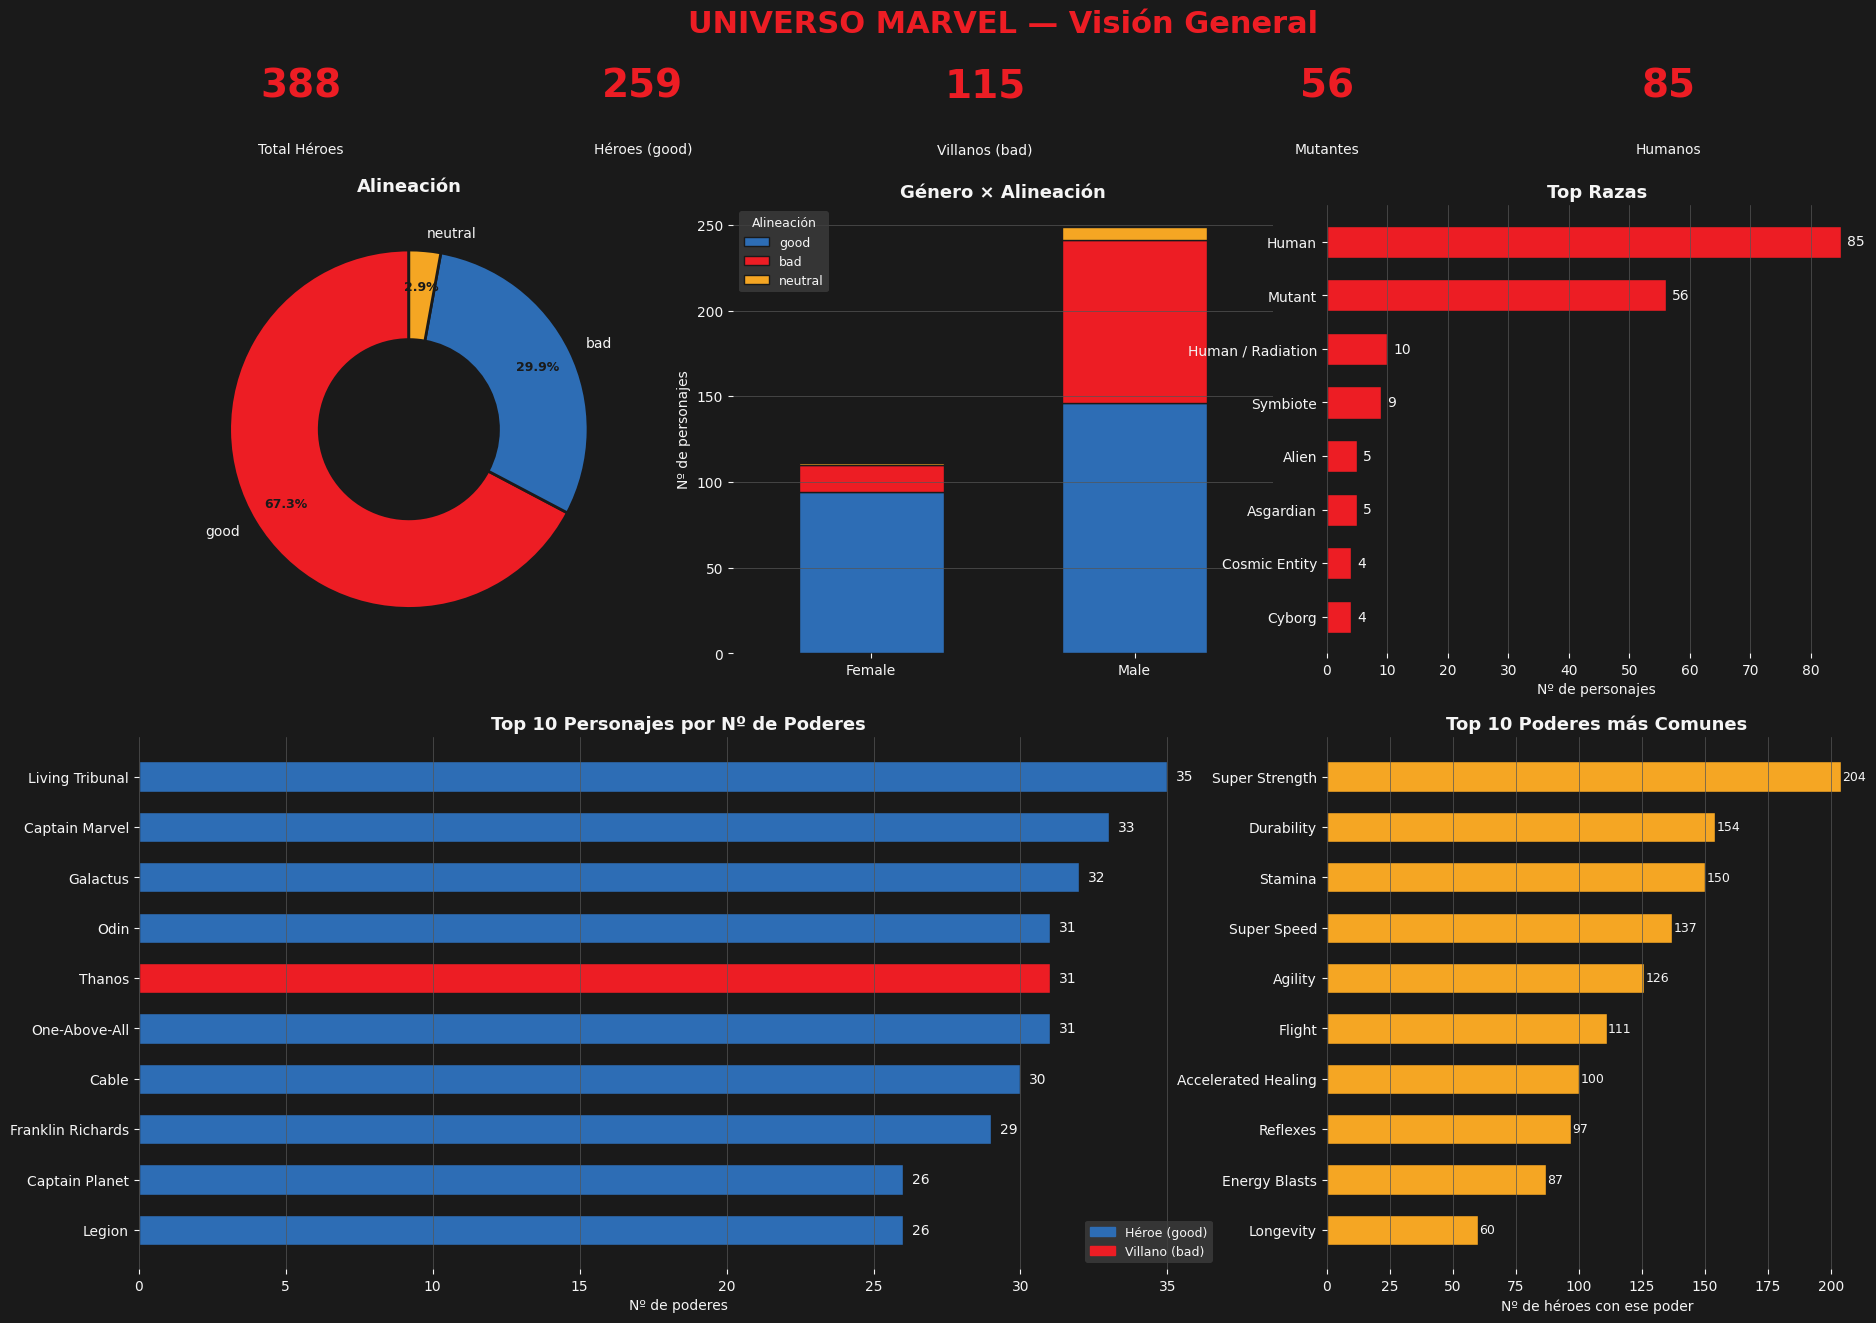

✅ Imagen guardada como dashboard1_marvel.png


In [ ]:
# ============================================================
#  5 — Visualizaciones Dashboard 1
# ============================================================
 
# Paleta Marvel
COLOR_RED    = "#ED1D24"
COLOR_DARK   = "#1A1A1A"
COLOR_GRAY   = "#3D3D3D"
COLOR_LIGHT  = "#F5F5F5"
COLOR_GOLD   = "#F5A623"
COLOR_BLUE   = "#2D6DB5"
 
plt.rcParams.update({
    "figure.facecolor": COLOR_DARK,
    "axes.facecolor":   COLOR_DARK,
    "axes.labelcolor":  COLOR_LIGHT,
    "text.color":       COLOR_LIGHT,
    "xtick.color":      COLOR_LIGHT,
    "ytick.color":      COLOR_LIGHT,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.spines.left":  False,
    "axes.spines.bottom":False,
    "font.family":      "sans-serif",
})
 
fig = plt.figure(figsize=(18, 14), facecolor=COLOR_DARK)
fig.suptitle("UNIVERSO MARVEL — Visión General", 
             fontsize=22, fontweight="bold", color=COLOR_RED, y=0.98)
 
# ── KPIs (fila superior) ─────────────────────────────────────────
kpi_data = {
    "Total Héroes":    len(marvel_full),
    "Héroes (good)":   (marvel_full["Alignment"] == "good").sum(),
    "Villanos (bad)":  (marvel_full["Alignment"] == "bad").sum(),
    "Mutantes":        (marvel_full["Race"] == "Mutant").sum(),
    "Humanos":         (marvel_full["Race"] == "Human").sum(),
}
 
for i, (label, value) in enumerate(kpi_data.items()):
    ax = fig.add_axes([0.03 + i * 0.19, 0.86, 0.16, 0.10])
    ax.set_facecolor(COLOR_GRAY)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis("off")
    ax.text(0.5, 0.65, str(value), ha="center", va="center",
            fontsize=28, fontweight="bold", color=COLOR_RED)
    ax.text(0.5, 0.20, label, ha="center", va="center",
            fontsize=10, color=COLOR_LIGHT)
 
# ── GRÁFICO 1: Donut Alineación ────────────────────────────────
ax1 = fig.add_axes([0.02, 0.52, 0.30, 0.32])
ax1.set_facecolor(COLOR_DARK)
 
align_counts = marvel_full["Alignment"].value_counts(dropna=True)
donut_colors = [COLOR_RED, COLOR_BLUE, COLOR_GOLD]
wedges, texts, autotexts = ax1.pie(
    align_counts.values,
    labels=align_counts.index,
    autopct="%1.1f%%",
    colors=donut_colors[:len(align_counts)],
    pctdistance=0.80,
    wedgeprops=dict(width=0.5, edgecolor=COLOR_DARK, linewidth=2),
    startangle=90
)
for t in texts:
    t.set_color(COLOR_LIGHT); t.set_fontsize(10)
for at in autotexts:
    at.set_color(COLOR_DARK); at.set_fontsize(9); at.set_fontweight("bold")
 
ax1.set_title("Alineación", fontsize=13, fontweight="bold",
              color=COLOR_LIGHT, pad=10)
 
# ── GRÁFICO 2: Género x Alineación (barras apiladas) ───────────
ax2 = fig.add_axes([0.35, 0.52, 0.30, 0.32])
ax2.set_facecolor(COLOR_DARK)
 
gender_align = marvel_full.dropna(subset=["Gender", "Alignment"])
pivot = gender_align.groupby(["Gender", "Alignment"]).size().unstack(fill_value=0)
pivot = pivot[["good", "bad", "neutral"]] if "neutral" in pivot.columns else pivot[["good", "bad"]]
 
pivot.plot(
    kind="bar",
    stacked=True,
    ax=ax2,
    color=[COLOR_BLUE, COLOR_RED, COLOR_GOLD][:len(pivot.columns)],
    edgecolor=COLOR_DARK,
    width=0.55
)
ax2.set_title("Género × Alineación", fontsize=13, fontweight="bold", color=COLOR_LIGHT)
ax2.set_xlabel("")
ax2.set_ylabel("Nº de personajes", color=COLOR_LIGHT)
ax2.tick_params(axis="x", rotation=0)
ax2.legend(title="Alineación", title_fontsize=9, fontsize=9,
           facecolor=COLOR_GRAY, edgecolor="none", labelcolor=COLOR_LIGHT)
ax2.grid(axis="y", color="#555555", linewidth=0.5)
 
# ── GRÁFICO 3: Top Razas (barras horizontales) ─────────────────
ax3 = fig.add_axes([0.68, 0.52, 0.30, 0.32])
ax3.set_facecolor(COLOR_DARK)
 
top_races = marvel_full["Race"].value_counts(dropna=True).head(8)
bars = ax3.barh(top_races.index[::-1], top_races.values[::-1],
                color=COLOR_RED, edgecolor=COLOR_DARK, height=0.6)
 
# Etiquetas de valor
for bar in bars:
    ax3.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=10, color=COLOR_LIGHT)
 
ax3.set_title("Top Razas", fontsize=13, fontweight="bold", color=COLOR_LIGHT)
ax3.set_xlabel("Nº de personajes", color=COLOR_LIGHT)
ax3.grid(axis="x", color="#555555", linewidth=0.5)
 
# ── GRÁFICO 4: Top 10 héroes con más poderes ──────────────────
ax4 = fig.add_axes([0.02, 0.08, 0.60, 0.38])
ax4.set_facecolor(COLOR_DARK)
 
top_heroes = (
    marvel_full[marvel_full["power_count"] > 0]
    .nlargest(10, "power_count")[["name", "power_count", "Alignment"]]
    .sort_values("power_count")
)
 
bar_colors = [COLOR_RED if a == "bad" else COLOR_BLUE 
              for a in top_heroes["Alignment"].fillna("good")]
 
bars4 = ax4.barh(top_heroes["name"], top_heroes["power_count"],
                 color=bar_colors, edgecolor=COLOR_DARK, height=0.6)
 
for bar in bars4:
    ax4.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=10, color=COLOR_LIGHT)
 
ax4.set_title("Top 10 Personajes por Nº de Poderes", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT)
ax4.set_xlabel("Nº de poderes", color=COLOR_LIGHT)
ax4.grid(axis="x", color="#555555", linewidth=0.5)
 
legend_patches = [
    mpatches.Patch(color=COLOR_BLUE, label="Héroe (good)"),
    mpatches.Patch(color=COLOR_RED,  label="Villano (bad)"),
]
ax4.legend(handles=legend_patches, facecolor=COLOR_GRAY,
           edgecolor="none", labelcolor=COLOR_LIGHT, fontsize=9)
 
# ── GRÁFICO 5: Los 10 poderes más comunes en Marvel ───────────
ax5 = fig.add_axes([0.68, 0.08, 0.30, 0.38])
ax5.set_facecolor(COLOR_DARK)
 
power_totals = marvel_full[power_cols].sum().sort_values(ascending=False).head(10)
 
bars5 = ax5.barh(power_totals.index[::-1], power_totals.values[::-1],
                 color=COLOR_GOLD, edgecolor=COLOR_DARK, height=0.6)
 
for bar in bars5:
    ax5.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=9, color=COLOR_LIGHT)
 
ax5.set_title("Top 10 Poderes más Comunes", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT)
ax5.set_xlabel("Nº de héroes con ese poder", color=COLOR_LIGHT)
ax5.grid(axis="x", color="#555555", linewidth=0.5)
 
plt.savefig("dashboard1_marvel.png", dpi=150, bbox_inches="tight",
            facecolor=COLOR_DARK)
plt.show()
print("✅ Imagen guardada como dashboard1_marvel.png")
 

In [ ]:
# ============================================================
#  6 — Exportar CSVs limpios para Power BI
# ============================================================
 
# CSV 1: datos de héroes limpios (sin poderes)
marvel_clean = marvel_full[["name", "Gender", "Race", "Alignment",
                             "Height", "Weight", "Eye color",
                             "Hair color", "Skin color", "power_count"]].copy()
 
marvel_clean.to_csv("marvel_heroes_clean.csv", index=False)
print("✅ Exportado: marvel_heroes_clean.csv")
 
# CSV 2: poderes por héroe (formato largo, más útil en Power BI)
marvel_powers_long = marvel_full[["name", "Alignment"] + power_cols].copy()
marvel_powers_long = marvel_powers_long.melt(
    id_vars=["name", "Alignment"],
    var_name="Power",
    value_name="Has_Power"
)
marvel_powers_long = marvel_powers_long[marvel_powers_long["Has_Power"] == 1].drop(columns="Has_Power")
marvel_powers_long.to_csv("marvel_powers_long.csv", index=False)
print("✅ Exportado: marvel_powers_long.csv")
 
# CSV 3: resumen de alineación para KPIs
summary = {
    "Total Heroes": [len(marvel_full)],
    "Good":         [(marvel_full["Alignment"] == "good").sum()],
    "Bad":          [(marvel_full["Alignment"] == "bad").sum()],
    "Neutral":      [(marvel_full["Alignment"] == "neutral").sum()],
    "Mutants":      [(marvel_full["Race"] == "Mutant").sum()],
    "Humans":       [(marvel_full["Race"] == "Human").sum()],
    "Avg Powers":   [round(marvel_full["power_count"].mean(), 1)],
}
pd.DataFrame(summary).to_csv("marvel_kpis.csv", index=False)
print("✅ Exportado: marvel_kpis.csv")
 
print("\n📁 Archivos listos para importar en Power BI:")
print("   → marvel_heroes_clean.csv  (tabla principal)")
print("   → marvel_powers_long.csv   (tabla de poderes en formato largo)")
print("   → marvel_kpis.csv          (KPIs para tarjetas)")
 

✅ Exportado: marvel_heroes_clean.csv
✅ Exportado: marvel_powers_long.csv
✅ Exportado: marvel_kpis.csv

📁 Archivos listos para importar en Power BI:
   → marvel_heroes_clean.csv  (tabla principal)
   → marvel_powers_long.csv   (tabla de poderes en formato largo)
   → marvel_kpis.csv          (KPIs para tarjetas)


### DASHBOARD 2

In [ ]:
# ============================================================
# MARVEL SUPERHEROES - DASHBOARD 2: Mapa de Poderes
# ============================================================
# IMPORTANTE: Ejecutar primero todas las celdas del Dashboard 1
# Este script asume que marvel_full y power_cols ya existen
 
# ============================================================
# 7 — Preparar datos para Dashboard 2
# ============================================================
 
## Asegurarnos de que las columnas de poderes son numéricas
marvel_full[power_cols] = marvel_full[power_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

# Razas con al menos 3 héroes (para que el gráfico tenga sentido)
races_valid = (
    marvel_full["Race"]
    .value_counts(dropna=True)
    .loc[lambda x: x >= 3]
    .index.tolist())
 
# Top 15 poderes globales
top15_powers = (
    marvel_full[power_cols]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .index.tolist())
 
# Tabla: raza × top 15 poderes (para heatmap)
race_power_matrix = (
    marvel_full[marvel_full["Race"].isin(races_valid)]
    .groupby("Race")[top15_powers]
    .sum())

## Convertir la matriz a números sí o sí
race_power_matrix = race_power_matrix.apply(pd.to_numeric, errors="coerce").fillna(0)
 
# Tabla interactiva: héroe y sus poderes
hero_powers_summary = (
    marvel_full[["name", "Alignment", "Race", "power_count"] + top15_powers]
    .dropna(subset=["power_count"])
    .sort_values("power_count", ascending=False)
    .reset_index(drop=True))
 
print("✅ Datos preparados")
print(f"   Razas en heatmap: {len(races_valid)}")
print(f"   Top poderes analizados: {len(top15_powers)}")
print(f"   Héroes en tabla interactiva: {len(hero_powers_summary)}")
 

✅ Datos preparados
   Razas en heatmap: 11
   Top poderes analizados: 15
   Héroes en tabla interactiva: 388


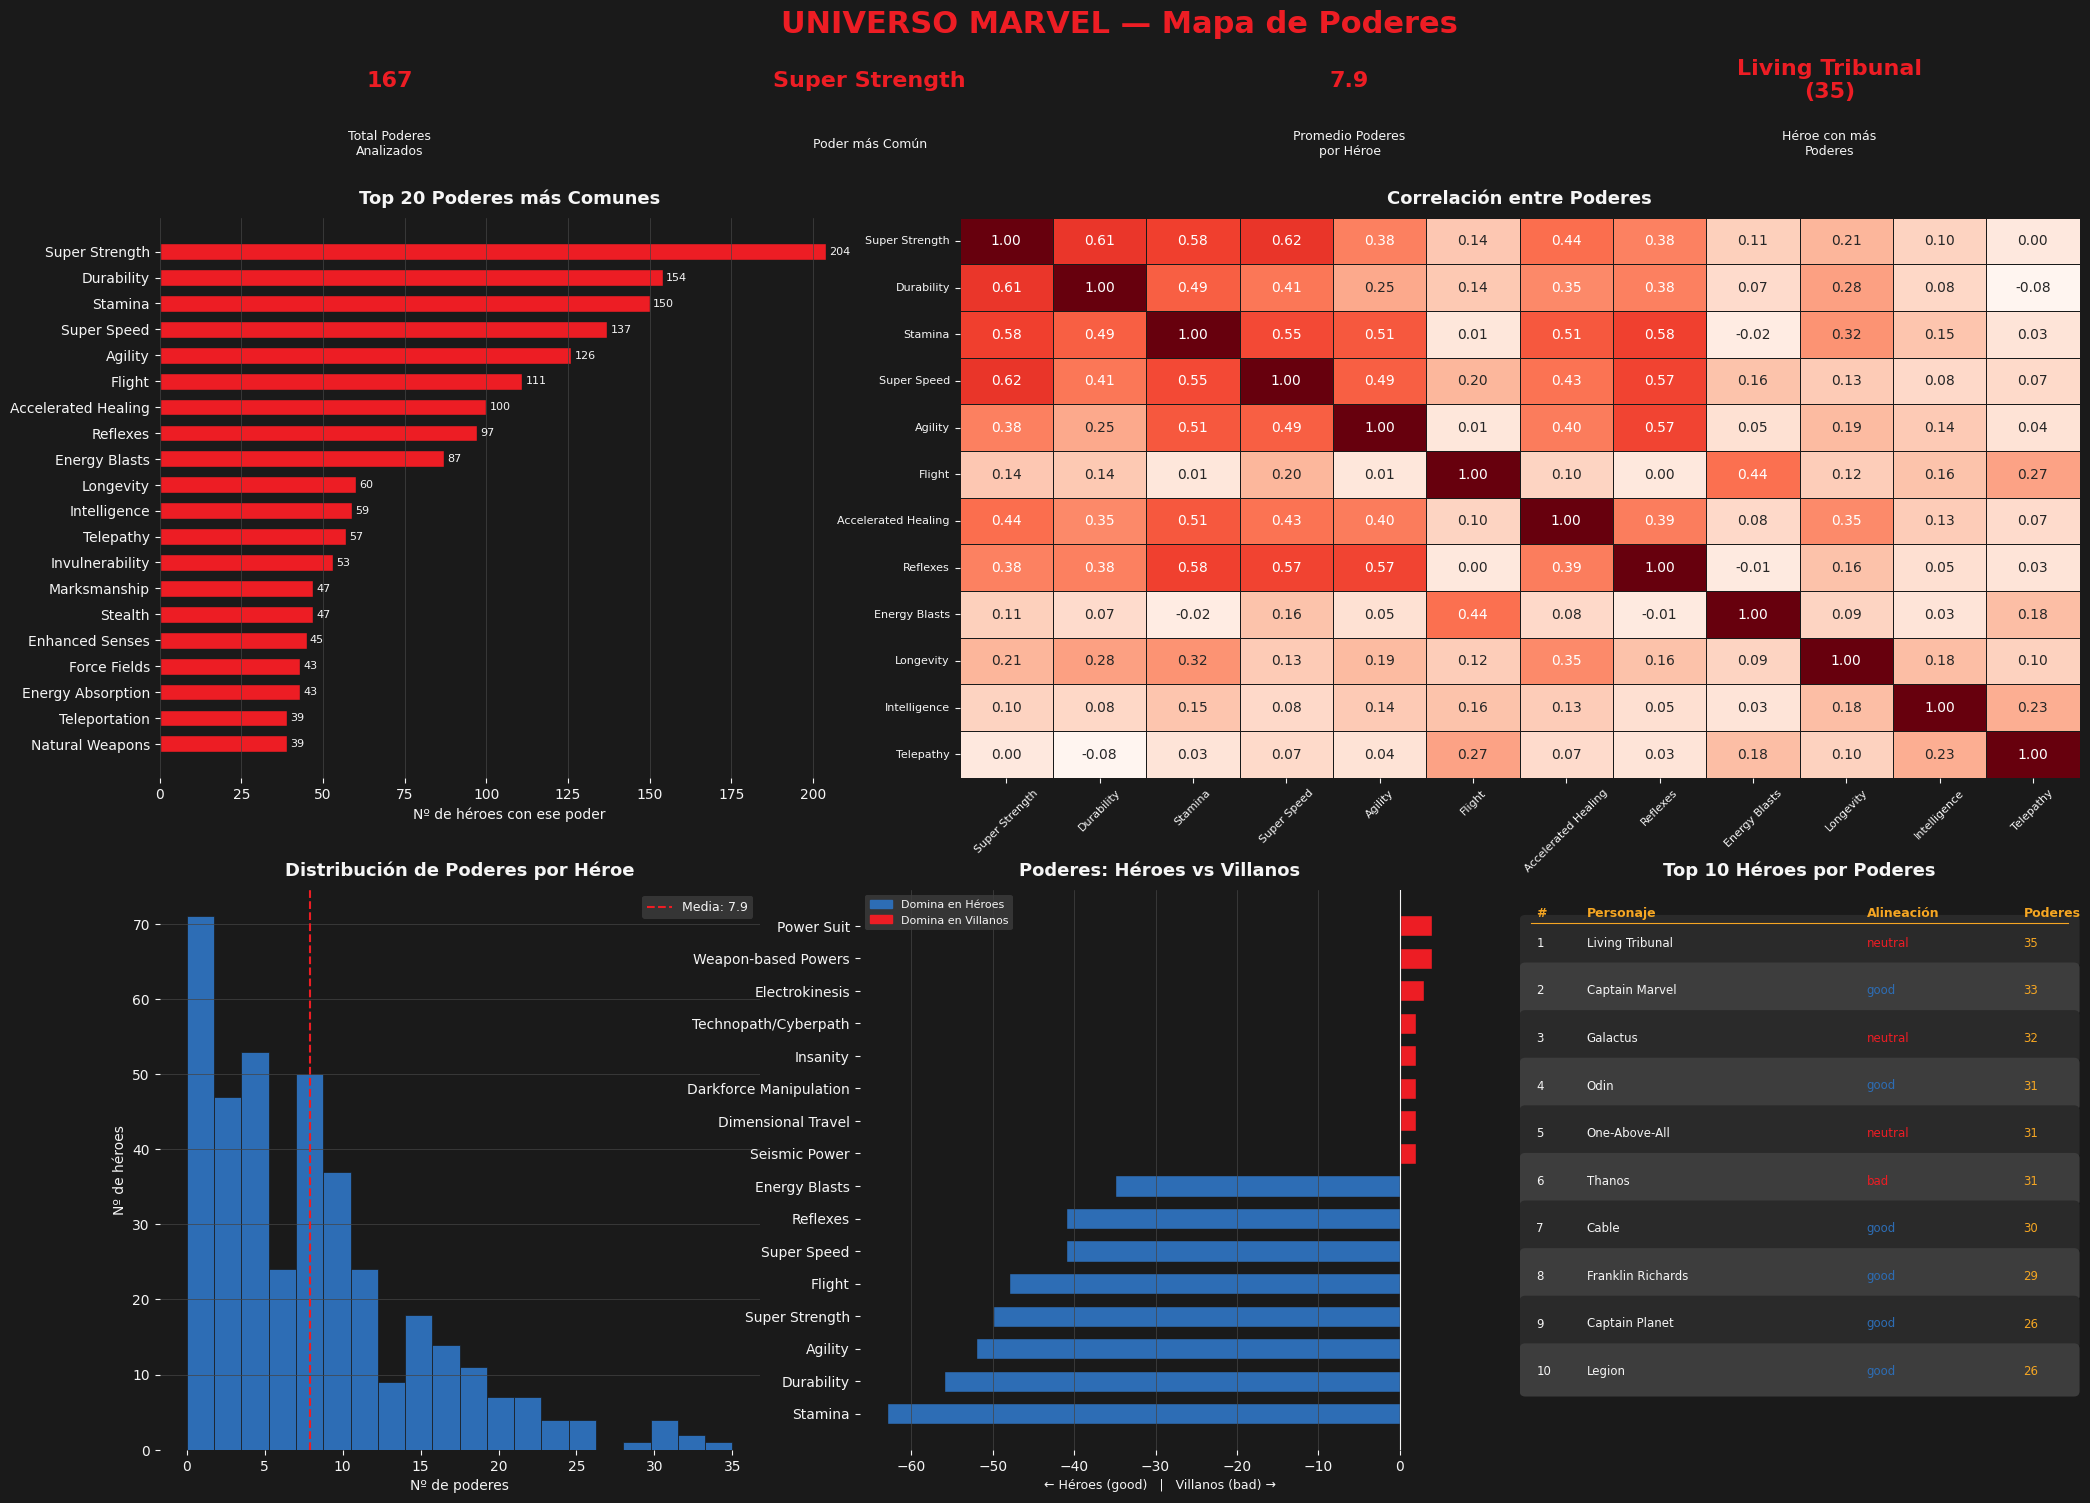

✅ Imagen guardada como dashboard2_marvel.png


In [ ]:
# ============================================================
#  8 — Visualizaciones Dashboard 2
# ============================================================
  
COLOR_RED   = "#ED1D24"
COLOR_DARK  = "#1A1A1A"
COLOR_GRAY  = "#3D3D3D"
COLOR_LIGHT = "#F5F5F5"
COLOR_GOLD  = "#F5A623"
COLOR_BLUE  = "#2D6DB5"
 
plt.rcParams.update({
    "figure.facecolor": COLOR_DARK,
    "axes.facecolor":   COLOR_DARK,
    "axes.labelcolor":  COLOR_LIGHT,
    "text.color":       COLOR_LIGHT,
    "xtick.color":      COLOR_LIGHT,
    "ytick.color":      COLOR_LIGHT,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.spines.left":   False,
    "axes.spines.bottom": False,
    "font.family":        "sans-serif",
})
 
fig = plt.figure(figsize=(20, 16), facecolor=COLOR_DARK)
fig.suptitle("UNIVERSO MARVEL — Mapa de Poderes", 
             fontsize=22, fontweight="bold", color=COLOR_RED, y=0.98)
 
# ── KPIs fila superior ────────────────────────────────────────
total_poderes     = len(power_cols)
poder_mas_comun   = marvel_full[power_cols].sum().idxmax()
promedio_poderes  = round(marvel_full["power_count"].mean(), 1)
heroe_max         = marvel_full.loc[marvel_full["power_count"].idxmax(), "name"]
max_poderes       = int(marvel_full["power_count"].max())
 
kpis = [
    ("Total Poderes\nAnalizados", str(total_poderes)),
    ("Poder más Común", poder_mas_comun),
    ("Promedio Poderes\npor Héroe", str(promedio_poderes)),
    (f"Héroe con más\nPoderes", f"{heroe_max}\n({max_poderes})"),
]
 
for i, (label, value) in enumerate(kpis):
    ax = fig.add_axes([0.03 + i * 0.24, 0.88, 0.21, 0.09])
    ax.set_facecolor(COLOR_GRAY)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis("off")
    ax.text(0.5, 0.62, value, ha="center", va="center",
            fontsize=16, fontweight="bold", color=COLOR_RED)
    ax.text(0.5, 0.18, label, ha="center", va="center",
            fontsize=9, color=COLOR_LIGHT)
 
# ── GRÁFICO 1: Top 20 poderes más comunes (barras horizontales) ─
ax1 = fig.add_axes([0.02, 0.50, 0.35, 0.35])
ax1.set_facecolor(COLOR_DARK)
 
top20 = marvel_full[power_cols].sum().sort_values(ascending=False).head(20)
 
bars = ax1.barh(
    top20.index[::-1], top20.values[::-1],
    color=COLOR_RED, edgecolor=COLOR_DARK, height=0.65)

for bar in bars:
    ax1.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=8, color=COLOR_LIGHT)
 
ax1.set_title("Top 20 Poderes más Comunes", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax1.set_xlabel("Nº de héroes con ese poder", color=COLOR_LIGHT)
ax1.grid(axis="x", color="#444444", linewidth=0.5)
 
# ── GRÁFICO 2: Heatmap de correlación entre poderes ───────────

marvel_full[power_cols] = marvel_full[power_cols].apply(
    pd.to_numeric, errors="coerce").fillna(0)

ax2 = fig.add_axes([0.42, 0.50, 0.56, 0.35])
ax2.set_facecolor(COLOR_DARK)

# Nos quedamos con los 12 poderes más comunes para que se lea bien
top_corr_powers = (
    marvel_full[power_cols]
    .sum()
    .sort_values(ascending=False)
    .head(12)
    .index)

# Matriz de correlación
corr_matrix = marvel_full[top_corr_powers].corr()

sns.heatmap(
    corr_matrix,
    ax=ax2,
    cmap="Reds",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    linecolor=COLOR_DARK,
    cbar=False)

ax2.set_title("Correlación entre Poderes", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)

ax2.set_xlabel("")
ax2.set_ylabel("")
ax2.tick_params(axis="x", rotation=45, labelsize=8)
ax2.tick_params(axis="y", rotation=0, labelsize=8)
 
# ── GRÁFICO 3: Distribución de power_count (histograma) ───────
ax3 = fig.add_axes([0.02, 0.08, 0.30, 0.35])
ax3.set_facecolor(COLOR_DARK)
 
ax3.hist(
    marvel_full["power_count"].dropna(),
    bins=20,
    color=COLOR_BLUE,
    edgecolor=COLOR_DARK,
    linewidth=0.5)

ax3.axvline(promedio_poderes, color=COLOR_RED, linestyle="--", linewidth=1.5,
            label=f"Media: {promedio_poderes}")
ax3.set_title("Distribución de Poderes por Héroe", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax3.set_xlabel("Nº de poderes", color=COLOR_LIGHT)
ax3.set_ylabel("Nº de héroes", color=COLOR_LIGHT)
ax3.legend(facecolor=COLOR_GRAY, edgecolor="none", labelcolor=COLOR_LIGHT, fontsize=9)
ax3.grid(axis="y", color="#444444", linewidth=0.5)
 
# ── GRÁFICO 4: Poderes exclusivos por alineación ──────────────
ax4 = fig.add_axes([0.37, 0.08, 0.30, 0.35])
ax4.set_facecolor(COLOR_DARK)
 
good = marvel_full[marvel_full["Alignment"] == "good"][power_cols].sum()
bad  = marvel_full[marvel_full["Alignment"] == "bad"][power_cols].sum()
 
# Diferencias: qué poderes dominan los malos vs buenos - barras horizontales divergentes
diff = (bad - good).sort_values()
top_bad  = diff.tail(8)   # poderes que dominan los villanos
top_good = diff.head(8)   # poderes que dominan los héroes
combined = pd.concat([top_good, top_bad]).sort_values()
 
colors_bar = [COLOR_BLUE if v < 0 else COLOR_RED for v in combined.values]
 
ax4.barh(combined.index, combined.values, color=colors_bar,
         edgecolor=COLOR_DARK, height=0.65)
ax4.axvline(0, color=COLOR_LIGHT, linewidth=0.8)
ax4.set_title("Poderes: Héroes vs Villanos", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax4.set_xlabel("← Héroes (good)   |   Villanos (bad) →", color=COLOR_LIGHT, fontsize=9)
ax4.grid(axis="x", color="#444444", linewidth=0.5)
 
legend_patches = [
    mpatches.Patch(color=COLOR_BLUE, label="Domina en Héroes"),
    mpatches.Patch(color=COLOR_RED,  label="Domina en Villanos"),
]
ax4.legend(handles=legend_patches, facecolor=COLOR_GRAY,
           edgecolor="none", labelcolor=COLOR_LIGHT, fontsize=8)
 
# ── GRÁFICO 5: Top 10 héroes con más poderes (tabla visual) ───
ax5 = fig.add_axes([0.70, 0.08, 0.28, 0.35])
ax5.set_facecolor(COLOR_GRAY)
ax5.axis("off")
 
top10 = (
    marvel_full[["name", "Alignment", "power_count"]]
    .dropna(subset=["power_count"])
    .nlargest(10, "power_count")
    .reset_index(drop=True))
 
ax5.set_title("Top 10 Héroes por Poderes", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
 
headers = ["#", "Personaje", "Alineación", "Poderes"]
col_x   = [0.03, 0.12, 0.62, 0.90]
 
# Cabecera
for j, (h, x) in enumerate(zip(headers, col_x)):
    ax5.text(x, 0.97, h, fontsize=9, fontweight="bold",
             color=COLOR_GOLD, va="top", transform=ax5.transAxes)
 
ax5.plot([0.02, 0.98],
    [0.94, 0.94],
    color=COLOR_GOLD,
    linewidth=0.8,
    transform=ax5.transAxes)
 
# Filas
for idx, row in top10.iterrows():
    y = 0.90 - idx * 0.085
    bg_color = "#2A2A2A" if idx % 2 == 0 else COLOR_GRAY
    rect = mpatches.FancyBboxPatch((0.01, y - 0.03), 0.98, 0.075,
                                    boxstyle="round,pad=0.01",
                                    facecolor=bg_color, edgecolor="none",
                                    transform=ax5.transAxes)
    ax5.add_patch(rect)
 
    align_color = COLOR_BLUE if row["Alignment"] == "good" else COLOR_RED
    row_data = [str(idx + 1), row["name"], row["Alignment"], str(int(row["power_count"]))]
    row_colors = [COLOR_LIGHT, COLOR_LIGHT, align_color, COLOR_GOLD]
 
    for j, (val, x, c) in enumerate(zip(row_data, col_x, row_colors)):
        ax5.text(x, y + 0.005, val, fontsize=8.5, color=c,
                 va="center", transform=ax5.transAxes)
 
plt.savefig("dashboard2_marvel.png", dpi=150, bbox_inches="tight",
            facecolor=COLOR_DARK)
plt.show()
print("✅ Imagen guardada como dashboard2_marvel.png")
 

In [30]:
# ============================================================
# 9 — Exportar datos del Dashboard 2 para Power BI
# ============================================================
 
# CSV 1: top poderes con conteo total
power_summary = (
    marvel_full[power_cols]
    .sum()
    .reset_index()
    .rename(columns={"index": "Power", 0: "Count"})
    .sort_values("Count", ascending=False)
)
power_summary.to_csv("marvel_power_summary.csv", index=False)
print("✅ Exportado: marvel_power_summary.csv")
 
# CSV 2: matriz raza × poder (para heatmap en Power BI)
race_power_matrix.reset_index().to_csv("marvel_race_power_matrix.csv", index=False)
print("✅ Exportado: marvel_race_power_matrix.csv")
 
# CSV 3: poderes por alineación (good vs bad)
align_powers = (
    marvel_full[marvel_full["Alignment"].isin(["good", "bad"])]
    .groupby("Alignment")[power_cols]
    .sum()
    .T
    .reset_index()
    .rename(columns={"index": "Power"})
)
align_powers["difference"] = align_powers["bad"] - align_powers["good"]
align_powers = align_powers.sort_values("difference", ascending=False)
align_powers.to_csv("marvel_powers_by_alignment.csv", index=False)
print("✅ Exportado: marvel_powers_by_alignment.csv")
 
print("\n📁 Archivos listos para Power BI (Dashboard 2):")
print("   → marvel_power_summary.csv       (barras top poderes)")
print("   → marvel_race_power_matrix.csv   (heatmap raza × poder)")
print("   → marvel_powers_by_alignment.csv (héroes vs villanos)")
 

✅ Exportado: marvel_power_summary.csv
✅ Exportado: marvel_race_power_matrix.csv
✅ Exportado: marvel_powers_by_alignment.csv

📁 Archivos listos para Power BI (Dashboard 2):
   → marvel_power_summary.csv       (barras top poderes)
   → marvel_race_power_matrix.csv   (heatmap raza × poder)
   → marvel_powers_by_alignment.csv (héroes vs villanos)


### DASHBOARD 3

In [ ]:
# ============================================================
# 10 — Preparar datos para Dashboard 3
# ============================================================
 
# Subsets principales
good     = marvel_full[marvel_full["Alignment"] == "good"].copy()
bad      = marvel_full[marvel_full["Alignment"] == "bad"].copy()
mujeres  = marvel_full[marvel_full["Gender"] == "Female"].copy()
hombres  = marvel_full[marvel_full["Gender"] == "Male"].copy()
heroinas = mujeres[mujeres["Alignment"] == "good"].copy()
villanas = mujeres[mujeres["Alignment"] == "bad"].copy()
 
# Top 10 poderes por alineación
top10_good = good[power_cols].sum().sort_values(ascending=False).head(10)
top10_bad  = bad[power_cols].sum().sort_values(ascending=False).head(10)
 
# Top 10 poderes heroínas
top10_heroinas = heroinas[power_cols].sum().sort_values(ascending=False).head(10)
 
# Razas mujeres
razas_mujeres = mujeres["Race"].value_counts(dropna=True).head(8)
 
# Conclusiones numéricas
pct_mujeres   = round(len(mujeres) / len(marvel_full) * 100, 1)
pct_hombres   = round(len(hombres) / len(marvel_full) * 100, 1)
avg_good      = round(good["power_count"].mean(), 1)
avg_bad       = round(bad["power_count"].mean(), 1)
avg_heroinas  = round(heroinas["power_count"].mean(), 1)
avg_villanas  = round(villanas["power_count"].mean(), 1) if len(villanas) > 0 else 0
 
print("✅ Datos preparados")
print(f"   Heroínas: {len(heroinas)} | Villanas: {len(villanas)}")
print(f"   % Mujeres en Marvel: {pct_mujeres}%")
print(f"   Avg poderes good: {avg_good} | bad: {avg_bad}")
print(f"   Avg poderes heroínas: {avg_heroinas} | villanas: {avg_villanas}")

✅ Datos preparados
   Heroínas: 94 | Villanas: 16
   % Mujeres en Marvel: 28.6%
   Avg poderes good: 7.6 | bad: 7.5
   Avg poderes heroínas: 6.8 | villanas: 7.6


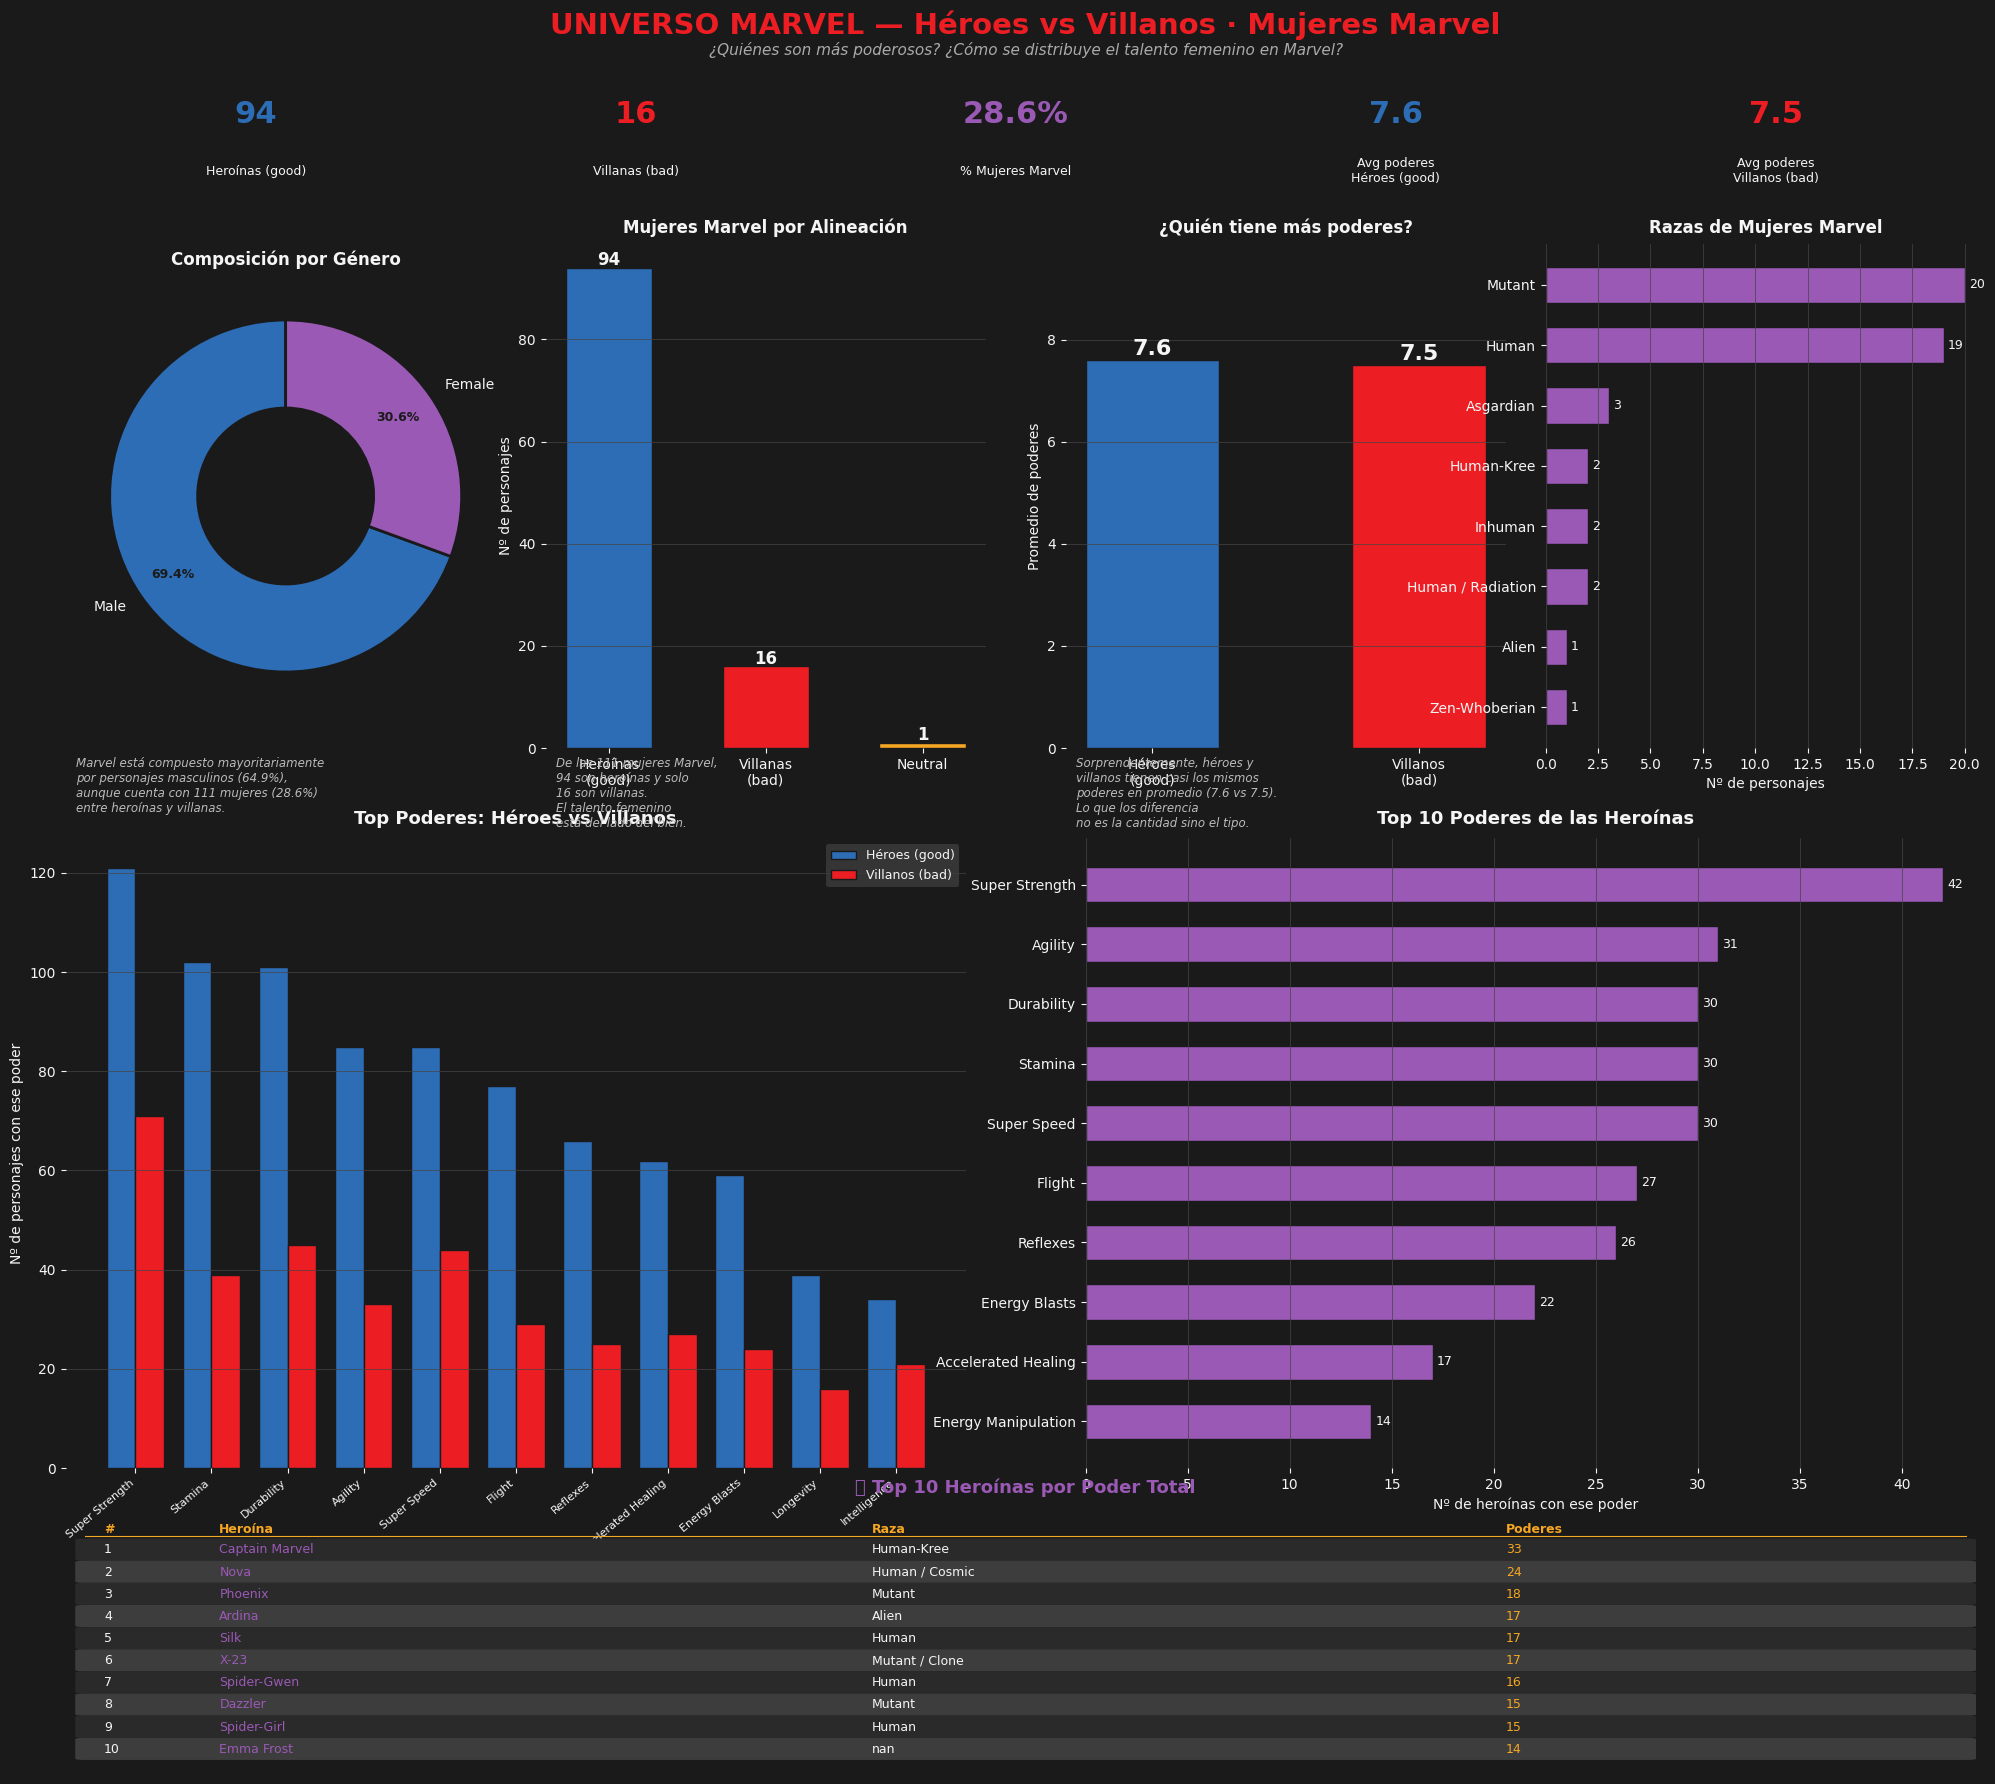

✅ Imagen guardada como dashboard3_marvel.png


In [ ]:
# ============================================================
# 11 — Visualizaciones Dashboard 3
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np  # ← añade esta línea

COLOR_RED    = "#ED1D24"
COLOR_DARK   = "#1A1A1A"
COLOR_GRAY   = "#3D3D3D"
COLOR_LIGHT  = "#F5F5F5"
COLOR_GOLD   = "#F5A623"
COLOR_BLUE   = "#2D6DB5"
COLOR_PURPLE = "#9B59B6"
COLOR_GREEN  = "#27AE60"
 
plt.rcParams.update({
    "figure.facecolor": COLOR_DARK,
    "axes.facecolor":   COLOR_DARK,
    "axes.labelcolor":  COLOR_LIGHT,
    "text.color":       COLOR_LIGHT,
    "xtick.color":      COLOR_LIGHT,
    "ytick.color":      COLOR_LIGHT,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.spines.left":   False,
    "axes.spines.bottom": False,
    "font.family":        "sans-serif",
})
 
fig = plt.figure(figsize=(20, 18), facecolor=COLOR_DARK)
fig.suptitle("UNIVERSO MARVEL — Héroes vs Villanos · Mujeres Marvel",
             fontsize=21, fontweight="bold", color=COLOR_RED, y=0.99)
 
# ── Título de contexto ───────────────────────────────────────
fig.text(0.5, 0.965,
         "¿Quiénes son más poderosos? ¿Cómo se distribuye el poder femenino en Marvel?",
         ha="center", fontsize=11, color="#AAAAAA", style="italic")
 
# ── KPIs fila superior ────────────────────────────────────────
kpis = [
    ("Heroínas (good)",   str(len(heroinas)),  COLOR_BLUE),
    ("Villanas (bad)",    str(len(villanas)),   COLOR_RED),
    ("% Mujeres Marvel",  f"{pct_mujeres}%",   COLOR_PURPLE),
    ("Avg poderes\nHéroes (good)", str(avg_good), COLOR_BLUE),
    ("Avg poderes\nVillanos (bad)", str(avg_bad), COLOR_RED),
]
 
for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_axes([0.03 + i * 0.19, 0.89, 0.17, 0.07])
    ax.set_facecolor(COLOR_GRAY)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis("off")
    ax.text(0.5, 0.60, value, ha="center", va="center",
            fontsize=22, fontweight="bold", color=color)
    ax.text(0.5, 0.15, label, ha="center", va="center",
            fontsize=9, color=COLOR_LIGHT)
 
# ── CONCLUSIÓN 1: Composición por género (donut) ──────────────
ax1 = fig.add_axes([0.02, 0.58, 0.22, 0.28])
ax1.set_facecolor(COLOR_DARK)
 
gender_counts = marvel_full["Gender"].value_counts(dropna=True)
wedges, texts, autotexts = ax1.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    colors=[COLOR_BLUE, COLOR_PURPLE],
    pctdistance=0.78,
    wedgeprops=dict(width=0.5, edgecolor=COLOR_DARK, linewidth=2),
    startangle=90
)
for t in texts:
    t.set_color(COLOR_LIGHT); t.set_fontsize(10)
for at in autotexts:
    at.set_color(COLOR_DARK); at.set_fontsize(9); at.set_fontweight("bold")
 
ax1.set_title("Composición por Género", fontsize=12,
              fontweight="bold", color=COLOR_LIGHT, pad=8)
 
# Conclusión textual
fig.text(0.025, 0.575,
         f"Marvel está compuesto mayoritariamente\npor personajes masculinos ({pct_hombres}%),\n"
         f"aunque cuenta con {len(mujeres)} mujeres ({pct_mujeres}%)\nentre heroínas y villanas.",
         fontsize=8.5, color="#BBBBBB", style="italic", va="top")
 
# ── CONCLUSIÓN 2: Heroínas vs Villanas ────────────────────────
ax2 = fig.add_axes([0.26, 0.58, 0.22, 0.28])
ax2.set_facecolor(COLOR_DARK)
 
fem_align = [len(heroinas), len(villanas),
             len(mujeres[mujeres["Alignment"] == "neutral"])]
fem_labels = ["Heroínas\n(good)", "Villanas\n(bad)", "Neutral"]
fem_colors = [COLOR_BLUE, COLOR_RED, COLOR_GOLD]
 
bars = ax2.bar(fem_labels, fem_align, color=fem_colors,
               edgecolor=COLOR_DARK, width=0.55)
for bar, val in zip(bars, fem_align):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
             str(val), ha="center", fontsize=12, fontweight="bold", color=COLOR_LIGHT)
 
ax2.set_title("Mujeres Marvel por Alineación", fontsize=12,
              fontweight="bold", color=COLOR_LIGHT, pad=8)
ax2.set_ylabel("Nº de personajes", color=COLOR_LIGHT)
ax2.grid(axis="y", color="#444444", linewidth=0.5)
 
fig.text(0.265, 0.575,
         f"De las {len(mujeres)} mujeres Marvel,\n{len(heroinas)} son heroínas y solo\n"
         f"{len(villanas)} son villanas.\nEl talento femenino\nestá del lado del bien.",
         fontsize=8.5, color="#BBBBBB", style="italic", va="top")
 
# ── CONCLUSIÓN 3: Avg poderes good vs bad (barras comparativas) ─
ax3 = fig.add_axes([0.52, 0.58, 0.22, 0.28])
ax3.set_facecolor(COLOR_DARK)
 
grupos    = ["Héroes\n(good)", "Villanos\n(bad)"]
avg_vals  = [avg_good, avg_bad]
avg_cols  = [COLOR_BLUE, COLOR_RED]
 
bars3 = ax3.bar(grupos, avg_vals, color=avg_cols, edgecolor=COLOR_DARK, width=0.5)
for bar, val in zip(bars3, avg_vals):
    ax3.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.1,
             str(val), ha="center", fontsize=16, fontweight="bold", color=COLOR_LIGHT)
 
ax3.set_title("¿Quién tiene más poderes?", fontsize=12,
              fontweight="bold", color=COLOR_LIGHT, pad=8)
ax3.set_ylabel("Promedio de poderes", color=COLOR_LIGHT)
ax3.set_ylim(0, max(avg_vals) * 1.3)
ax3.grid(axis="y", color="#444444", linewidth=0.5)
 
fig.text(0.525, 0.575,
         f"Sorprendentemente, héroes y\nvillanos tienen casi los mismos\n"
         f"poderes en promedio ({avg_good} vs {avg_bad}).\nLo que los diferencia\nno es la cantidad sino el tipo.",
         fontsize=8.5, color="#BBBBBB", style="italic", va="top")
 
# ── CONCLUSIÓN 4: Razas de mujeres Marvel ─────────────────────
ax4 = fig.add_axes([0.76, 0.58, 0.22, 0.28])
ax4.set_facecolor(COLOR_DARK)
 
bars4 = ax4.barh(razas_mujeres.index[::-1], razas_mujeres.values[::-1],
                 color=COLOR_PURPLE, edgecolor=COLOR_DARK, height=0.6)
for bar in bars4:
    ax4.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=9, color=COLOR_LIGHT)
 
ax4.set_title("Razas de Mujeres Marvel", fontsize=12,
              fontweight="bold", color=COLOR_LIGHT, pad=8)
ax4.set_xlabel("Nº de personajes", color=COLOR_LIGHT)
ax4.grid(axis="x", color="#444444", linewidth=0.5)
 
# ── GRÁFICO 5: Top 10 poderes Héroes vs Villanos (paralelo) ───
ax5 = fig.add_axes([0.02, 0.18, 0.45, 0.35])
ax5.set_facecolor(COLOR_DARK)
 
# Unión de top poderes de ambos grupos
all_top = list(dict.fromkeys(list(top10_good.index) + list(top10_bad.index)))
good_vals = [int(good[p].sum()) for p in all_top]
bad_vals  = [int(bad[p].sum())  for p in all_top]
 
x     = np.arange(len(all_top))
width = 0.38
 
ax5.bar(x - width / 2, good_vals, width, label="Héroes (good)",
        color=COLOR_BLUE, edgecolor=COLOR_DARK)
ax5.bar(x + width / 2, bad_vals,  width, label="Villanos (bad)",
        color=COLOR_RED,  edgecolor=COLOR_DARK)
 
ax5.set_title("Top Poderes: Héroes vs Villanos", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax5.set_xticks(x)
ax5.set_xticklabels(all_top, rotation=40, ha="right", fontsize=8)
ax5.set_ylabel("Nº de personajes con ese poder", color=COLOR_LIGHT)
ax5.legend(facecolor=COLOR_GRAY, edgecolor="none", labelcolor=COLOR_LIGHT, fontsize=9)
ax5.grid(axis="y", color="#444444", linewidth=0.5)
 
# ── GRÁFICO 6: Top 10 poderes heroínas ────────────────────────
ax6 = fig.add_axes([0.53, 0.18, 0.45, 0.35])
ax6.set_facecolor(COLOR_DARK)
 
bars6 = ax6.barh(top10_heroinas.index[::-1], top10_heroinas.values[::-1],
                 color=COLOR_PURPLE, edgecolor=COLOR_DARK, height=0.6)
for bar in bars6:
    ax6.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2,
             str(int(bar.get_width())), va="center", fontsize=9, color=COLOR_LIGHT)
 
ax6.set_title("Top 10 Poderes de las Heroínas", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax6.set_xlabel("Nº de heroínas con ese poder", color=COLOR_LIGHT)
ax6.grid(axis="x", color="#444444", linewidth=0.5)
 
# ── TABLA: Top 10 heroínas por poder total ─────────────────────
ax7 = fig.add_axes([0.02, 0.01, 0.96, 0.15])
ax7.set_facecolor(COLOR_GRAY)
ax7.axis("off")
ax7.set_title("🏆 Top 10 Heroínas por Poder Total", fontsize=13,
              fontweight="bold", color=COLOR_PURPLE, pad=8)
 
top10_h = (
    heroinas[["name", "Race", "power_count"]]
    .dropna(subset=["power_count"])
    .nlargest(10, "power_count")
    .reset_index(drop=True)
)
 
headers  = ["#", "Heroína", "Raza", "Poderes"]
col_x    = [0.02, 0.08, 0.42, 0.75]
 
for j, (h, x) in enumerate(zip(headers, col_x)):
    ax7.text(x, 0.93, h, fontsize=9, fontweight="bold",
             color=COLOR_GOLD, va="top", transform=ax7.transAxes)
 
ax7.plot([0.01, 0.99], [0.88, 0.88], color=COLOR_GOLD,
         linewidth=0.8, transform=ax7.transAxes)
 
for idx, row in top10_h.iterrows():
    y = 0.82 - idx * 0.082
    rect = mpatches.FancyBboxPatch(
        (0.01, y - 0.025), 0.98, 0.072,
        boxstyle="round,pad=0.005",
        facecolor="#2A2A2A" if idx % 2 == 0 else COLOR_GRAY,
        edgecolor="none", transform=ax7.transAxes
    )
    ax7.add_patch(rect)
    row_data   = [str(idx + 1), row["name"], str(row["Race"]) if row["Race"] else "—", str(int(row["power_count"]))]
    row_colors = [COLOR_LIGHT, COLOR_PURPLE, COLOR_LIGHT, COLOR_GOLD]
    for val, x, c in zip(row_data, col_x, row_colors):
        ax7.text(x, y + 0.01, val, fontsize=9, color=c,
                 va="center", transform=ax7.transAxes)
 
plt.savefig("dashboard3_marvel.png", dpi=150, bbox_inches="tight",
            facecolor=COLOR_DARK)
plt.show()
print("✅ Imagen guardada como dashboard3_marvel.png")
 

In [ ]:
# ============================================================
# 12 — Exportar datos del Dashboard 3 para Power BI
# ============================================================

# CSV 1: resumen género × alineación
gender_align_df = (
    marvel_full.dropna(subset=["Gender", "Alignment"])
    .groupby(["Gender", "Alignment"])
    .size()
    .reset_index(name="Count")
)
gender_align_df.to_csv("marvel_gender_alignment.csv", index=False)
print("✅ Exportado: marvel_gender_alignment.csv")

# CSV 2: top poderes por alineación (ya existe del DS2 pero con más detalle)
top_powers_align = pd.DataFrame({
    "Power":      all_top,
    "Good_count": good_vals,
    "Bad_count":  bad_vals,
})
top_powers_align.to_csv("marvel_top_powers_alignment.csv", index=False)
print("✅ Exportado: marvel_top_powers_alignment.csv")

# CSV 3: tabla mujeres Marvel completa
mujeres_export = marvel_full[marvel_full["Gender"] == "Female"][
    ["name", "Alignment", "Race", "power_count"]
].copy()
mujeres_export.to_csv("marvel_women.csv", index=False)
print("✅ Exportado: marvel_women.csv")

print("\n📁 Archivos listos para Power BI (Dashboard 3):")
print("   → marvel_gender_alignment.csv      (género × alineación)")
print("   → marvel_top_powers_alignment.csv  (poderes good vs bad)")
print("   → marvel_women.csv                 (tabla mujeres Marvel)")


✅ Exportado: marvel_gender_alignment.csv
✅ Exportado: marvel_top_powers_alignment.csv
✅ Exportado: marvel_women.csv

📁 Archivos listos para Power BI (Dashboard 3):
   → marvel_gender_alignment.csv      (género × alineación)
   → marvel_top_powers_alignment.csv  (poderes good vs bad)
   → marvel_women.csv                 (tabla mujeres Marvel)


In [ ]:
# ============================================================
# MARVEL SUPERHEROES - DASHBOARD 4: Rankings de Poder + Buscador
# ============================================================
# IMPORTANTE: Ejecutar primero todas las celdas del DashboardD.1 (Celdas 1-6)
# El script asume que marvel_full y power_cols ya existen

# ============================================================
# 13 — Preparar datos para Dashboard 4
# ============================================================

# Top 10 por cada categoría
# Desempate: en caso de empate en el poder específico, se usa power_count

def top_por_poder(df, poder, n=10):
    """Héroes que tienen ese poder, ordenados por power_count total."""
    return (
        df[df[poder] == 1][["name", "Alignment", "Gender", "Race", "power_count"]]
        .sort_values("power_count", ascending=False)
        .head(n)
        .reset_index(drop=True)
    )

top_total      = marvel_full.nlargest(10, "power_count")[["name", "Alignment", "Gender", "Race", "power_count"]].reset_index(drop=True)
top_intelig    = top_por_poder(marvel_full, "Intelligence")
top_fuerza     = top_por_poder(marvel_full, "Super Strength")
top_velocidad  = top_por_poder(marvel_full, "Super Speed")
top_vuelo      = top_por_poder(marvel_full, "Flight")
top_telepatia  = top_por_poder(marvel_full, "Telepathy")

# Conteos para KPIs
n_intelligence = int(marvel_full["Intelligence"].sum())
n_strength     = int(marvel_full["Super Strength"].sum())
n_speed        = int(marvel_full["Super Speed"].sum())
n_flight       = int(marvel_full["Flight"].sum())
n_telepathy    = int(marvel_full["Telepathy"].sum())
max_powers     = int(marvel_full["power_count"].max())
top_hero_name  = marvel_full.loc[marvel_full["power_count"].idxmax(), "name"]

print("✅ Datos preparados")
print(f"   Héroes con Inteligencia: {n_intelligence}")
print(f"   Héroes con Super Fuerza: {n_strength}")
print(f"   Héroes con Super Velocidad: {n_speed}")
print(f"   Héroes con Vuelo: {n_flight}")
print(f"   Héroe más poderoso: {top_hero_name} ({max_powers} poderes)")

✅ Datos preparados
   Héroes con Inteligencia: 59
   Héroes con Super Fuerza: 204
   Héroes con Super Velocidad: 137
   Héroes con Vuelo: 111
   Héroe más poderoso: Living Tribunal (35 poderes)


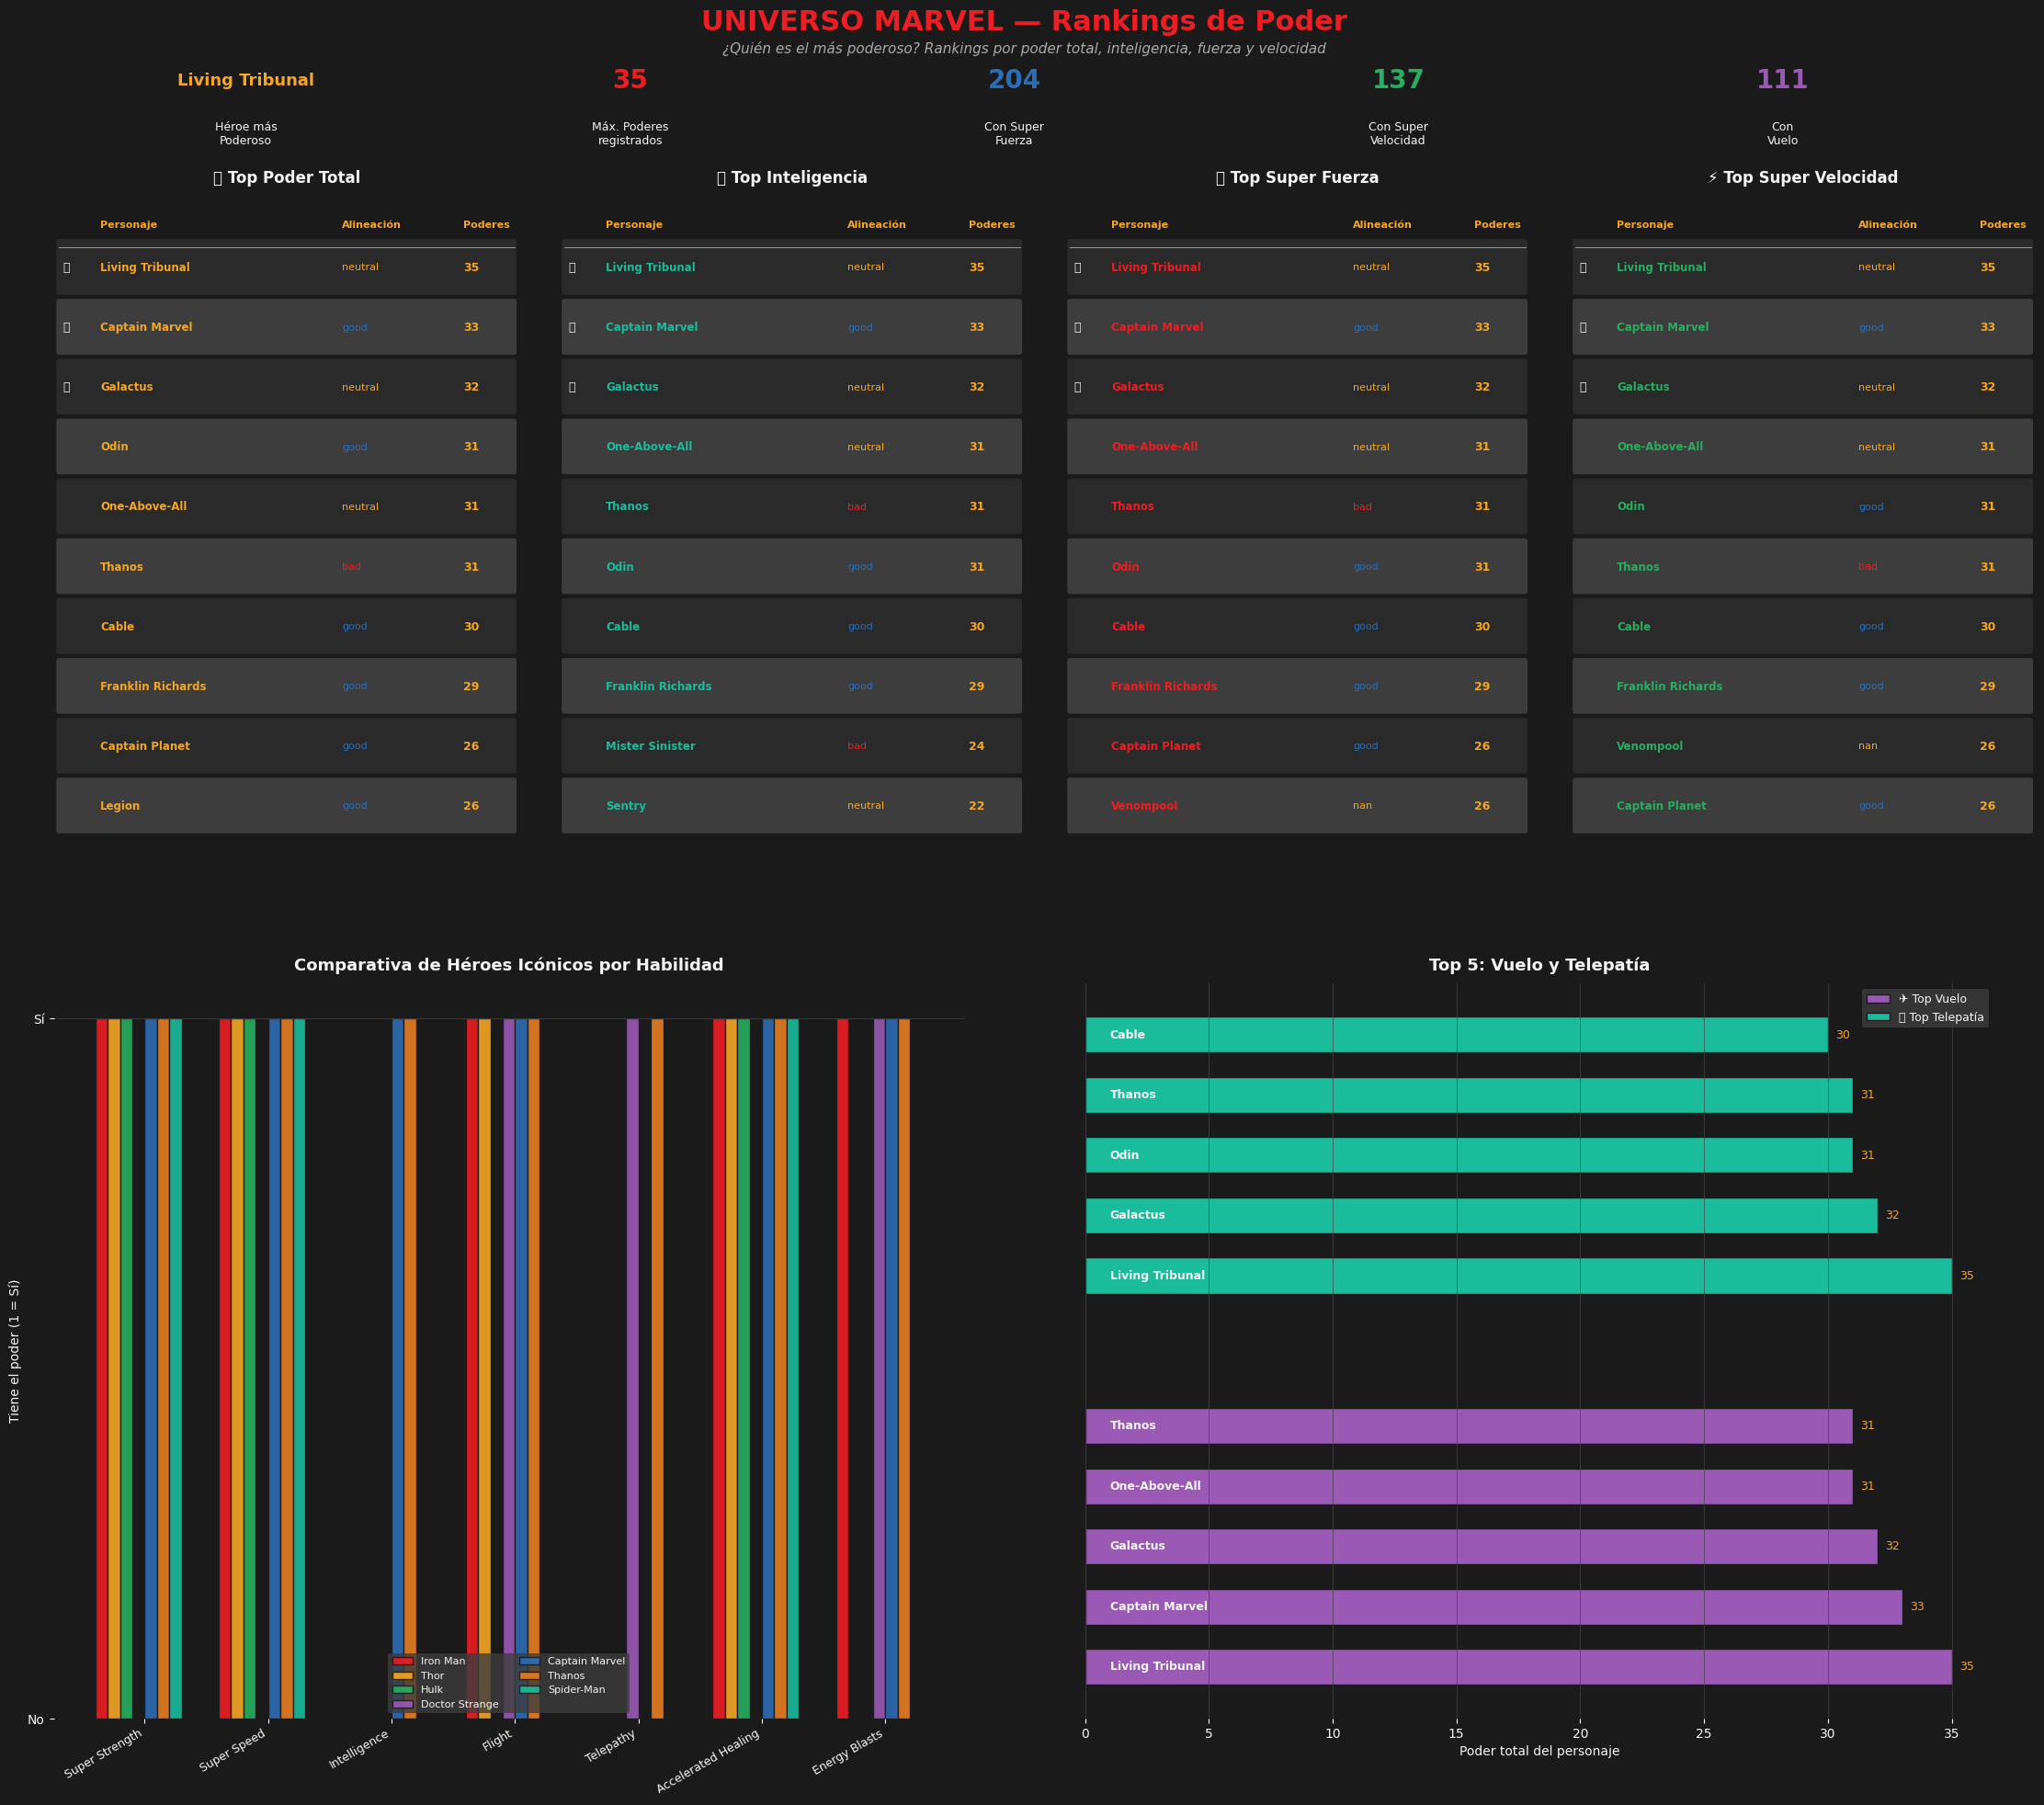

✅ Imagen guardada como dashboard4_marvel.png


In [ ]:
# ============================================================
# 14 — Visualizaciones Dashboard 4
# ============================================================


COLOR_RED    = "#ED1D24"
COLOR_DARK   = "#1A1A1A"
COLOR_GRAY   = "#3D3D3D"
COLOR_LIGHT  = "#F5F5F5"
COLOR_GOLD   = "#F5A623"
COLOR_BLUE   = "#2D6DB5"
COLOR_PURPLE = "#9B59B6"
COLOR_GREEN  = "#27AE60"
COLOR_TEAL   = "#1ABC9C"

plt.rcParams.update({
    "figure.facecolor": COLOR_DARK,
    "axes.facecolor":   COLOR_DARK,
    "axes.labelcolor":  COLOR_LIGHT,
    "text.color":       COLOR_LIGHT,
    "xtick.color":      COLOR_LIGHT,
    "ytick.color":      COLOR_LIGHT,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.spines.left":   False,
    "axes.spines.bottom": False,
    "font.family":        "sans-serif",
})

fig = plt.figure(figsize=(22, 20), facecolor=COLOR_DARK)
fig.suptitle("UNIVERSO MARVEL — Rankings de Poder",
             fontsize=22, fontweight="bold", color=COLOR_RED, y=0.99)

fig.text(0.5, 0.966,
         "¿Quién es el más poderoso? Rankings por poder total, inteligencia, fuerza y velocidad",
         ha="center", fontsize=11, color="#AAAAAA", style="italic")

# ── KPIs fila superior ────────────────────────────────────────
kpis = [
    ("Héroe más\nPoderoso",       top_hero_name,       COLOR_GOLD),
    ("Máx. Poderes\nregistrados", str(max_powers),     COLOR_RED),
    ("Con Super\nFuerza",         str(n_strength),     COLOR_BLUE),
    ("Con Super\nVelocidad",      str(n_speed),        COLOR_GREEN),
    ("Con\nVuelo",                str(n_flight),       COLOR_PURPLE),
]

for i, (label, value, color) in enumerate(kpis):
    ax = fig.add_axes([0.03 + i * 0.19, 0.915, 0.17, 0.06])
    ax.set_facecolor(COLOR_GRAY)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis("off")
    fontsize = 13 if len(value) > 10 else 20
    ax.text(0.5, 0.60, value, ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color=color)
    ax.text(0.5, 0.12, label, ha="center", va="center",
            fontsize=9, color=COLOR_LIGHT)

# ── Función para tablas de ranking ─────────────────────
def draw_ranking_table(ax, df, title, name_color, medal_colors=None):
    ax.set_facecolor(COLOR_GRAY)
    ax.axis("off")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=12, fontweight="bold",
                 color=COLOR_LIGHT, pad=8)

    medals = ["🥇", "🥈", "🥉"] + ["  " for _ in range(7)]
    headers  = ["", "Personaje", "Alineación", "Poderes"]
    col_x    = [0.02, 0.10, 0.62, 0.88]

    for j, (h, x) in enumerate(zip(headers, col_x)):
        ax.text(x, 0.96, h, fontsize=8, fontweight="bold",
                color=COLOR_GOLD, va="top", transform=ax.transAxes)

    ax.plot([0.01, 0.99], [0.92, 0.92], color=COLOR_GOLD,
        linewidth=0.6, transform=ax.transAxes)

    for idx, row in df.iterrows():
        y = 0.88 - idx * 0.088
        bg = "#2A2A2A" if idx % 2 == 0 else COLOR_GRAY
        rect = mpatches.FancyBboxPatch(
            (0.01, y - 0.025), 0.98, 0.072,
            boxstyle="round,pad=0.005",
            facecolor=bg, edgecolor="none",
            transform=ax.transAxes
        )
        ax.add_patch(rect)

        align_color = COLOR_BLUE if row["Alignment"] == "good" else (
                      COLOR_RED  if row["Alignment"] == "bad"  else COLOR_GOLD)

        ax.text(col_x[0], y + 0.01, medals[idx],   fontsize=9,  color=COLOR_LIGHT, va="center", transform=ax.transAxes)
        ax.text(col_x[1], y + 0.01, row["name"],   fontsize=8.5, color=name_color, va="center", transform=ax.transAxes, fontweight="bold")
        ax.text(col_x[2], y + 0.01, str(row["Alignment"]) if row["Alignment"] else "—",
                fontsize=8, color=align_color, va="center", transform=ax.transAxes)
        ax.text(col_x[3], y + 0.01, str(int(row["power_count"])),
                fontsize=9, color=COLOR_GOLD, va="center", transform=ax.transAxes, fontweight="bold")

# ── RANKING 1: Top poder total ────────────────────────────────
ax1 = fig.add_axes([0.02, 0.52, 0.23, 0.37])
draw_ranking_table(ax1, top_total, "🏆 Top Poder Total", COLOR_GOLD)

# ── RANKING 2: Top Inteligencia ───────────────────────────────
ax2 = fig.add_axes([0.27, 0.52, 0.23, 0.37])
draw_ranking_table(ax2, top_intelig, "🧠 Top Inteligencia", COLOR_TEAL)

# ── RANKING 3: Top Fuerza ─────────────────────────────────────
ax3 = fig.add_axes([0.52, 0.52, 0.23, 0.37])
draw_ranking_table(ax3, top_fuerza, "💪 Top Super Fuerza", COLOR_RED)

# ── RANKING 4: Top Velocidad ──────────────────────────────────
ax4 = fig.add_axes([0.77, 0.52, 0.23, 0.37])
draw_ranking_table(ax4, top_velocidad, "⚡ Top Super Velocidad", COLOR_GREEN)

# ── GRÁFICO: Radar / comparativa 5 héroes icónicos ─────────── (valorar sustituir por buscador interactivo)
ax5 = fig.add_axes([0.02, 0.06, 0.45, 0.40])
ax5.set_facecolor(COLOR_DARK)

heroes_iconicos = ["Iron Man", "Thor", "Hulk", "Doctor Strange", "Captain Marvel",
                   "Thanos", "Spider-Man"]
heroes_found = [h for h in heroes_iconicos if h in marvel_full["name"].values]

categorias = ["Super Strength", "Super Speed", "Intelligence",
              "Flight", "Telepathy", "Accelerated Healing", "Energy Blasts"]

hero_data = {}
for h in heroes_found:
    row = marvel_full[marvel_full["name"] == h].iloc[0]
    hero_data[h] = [int(row[c]) if c in row and not pd.isna(row[c]) else 0 for c in categorias]

x      = np.arange(len(categorias))
width  = 0.10
colors_h = [COLOR_RED, COLOR_GOLD, COLOR_GREEN, COLOR_PURPLE,
            COLOR_BLUE, "#E67E22", COLOR_TEAL]

for i, (hero, vals) in enumerate(hero_data.items()):
    offset = (i - len(hero_data) / 2) * width
    ax5.bar(x + offset, vals, width, label=hero,
            color=colors_h[i], edgecolor=COLOR_DARK, alpha=0.9)

ax5.set_title("Comparativa de Héroes Icónicos por Habilidad",
              fontsize=13, fontweight="bold", color=COLOR_LIGHT, pad=10)
ax5.set_xticks(x)
ax5.set_xticklabels(categorias, rotation=30, ha="right", fontsize=9)
ax5.set_ylabel("Tiene el poder (1 = Sí)", color=COLOR_LIGHT)
ax5.set_yticks([0, 1])
ax5.set_yticklabels(["No", "Sí"])
ax5.legend(facecolor=COLOR_GRAY, edgecolor="none", labelcolor=COLOR_LIGHT,
           fontsize=8, ncol=2)
ax5.grid(axis="y", color="#444444", linewidth=0.5)

# ── GRÁFICO: Top vuelo + telepatía (barras horizontales dobles) ─
ax6 = fig.add_axes([0.53, 0.06, 0.45, 0.40])
ax6.set_facecolor(COLOR_DARK)

# Combinar top vuelo y telepatía en un gráfico de barras
top_vuelo_5   = top_vuelo.head(5)
top_telepatia_5 = top_telepatia.head(5)

y1 = np.arange(len(top_vuelo_5))
y2 = np.arange(len(top_telepatia_5)) + len(top_vuelo_5) + 1.5

bars_v = ax6.barh(y1, top_vuelo_5["power_count"],
                  color=COLOR_PURPLE, edgecolor=COLOR_DARK, height=0.6, label="✈️ Top Vuelo")
bars_t = ax6.barh(y2, top_telepatia_5["power_count"],
                  color=COLOR_TEAL, edgecolor=COLOR_DARK, height=0.6, label="🔮 Top Telepatía")

for bar, (_, row) in zip(bars_v, top_vuelo_5.iterrows()):
    ax6.text(1, bar.get_y() + bar.get_height() / 2,
             row["name"], va="center", fontsize=9, color=COLOR_LIGHT, fontweight="bold")
    ax6.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
             str(int(row["power_count"])), va="center", fontsize=9, color=COLOR_GOLD)

for bar, (_, row) in zip(bars_t, top_telepatia_5.iterrows()):
    ax6.text(1, bar.get_y() + bar.get_height() / 2,
             row["name"], va="center", fontsize=9, color=COLOR_LIGHT, fontweight="bold")
    ax6.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
             str(int(row["power_count"])), va="center", fontsize=9, color=COLOR_GOLD)

ax6.set_yticks([])
ax6.set_title("Top 5: Vuelo y Telepatía", fontsize=13,
              fontweight="bold", color=COLOR_LIGHT, pad=10)
ax6.set_xlabel("Poder total del personaje", color=COLOR_LIGHT)
ax6.legend(facecolor=COLOR_GRAY, edgecolor="none", labelcolor=COLOR_LIGHT, fontsize=9)
ax6.grid(axis="x", color="#444444", linewidth=0.5)

plt.savefig("dashboard4_marvel.png", dpi=150, bbox_inches="tight",
            facecolor=COLOR_DARK)
plt.show()
print("✅ Imagen guardada como dashboard4_marvel.png")


In [ ]:
# ============================================================
# 15 — Exportar datos del Dashboard 4 para Power BI
# ============================================================

# CSV rankings
top_total.to_csv("ranking_poder_total.csv", index=False)
top_intelig.to_csv("ranking_inteligencia.csv", index=False)
top_fuerza.to_csv("ranking_fuerza.csv", index=False)
top_velocidad.to_csv("ranking_velocidad.csv", index=False)
top_vuelo.to_csv("ranking_vuelo.csv", index=False)
top_telepatia.to_csv("ranking_telepatia.csv", index=False)

print("✅ Rankings exportados (6 CSVs)")

# CSV maestro para buscador (todos los héroes + poderes relevantes)
poderes_buscador = ["Intelligence", "Super Strength", "Super Speed",
                    "Flight", "Telepathy", "Accelerated Healing",
                    "Energy Blasts", "Telekinesis", "Invisibility",
                    "Durability", "Stamina", "Agility", "Reflexes"]

buscador_df = marvel_full[["name", "Gender", "Race", "Alignment",
                            "Height", "Weight", "power_count"] + poderes_buscador].copy()
buscador_df.to_csv("marvel_buscador.csv", index=False)
print("✅ Exportado: marvel_buscador.csv (para buscador interactivo)")

print("\n📁 Archivos listos para Power BI (Dashboard 4):")
print("   → ranking_poder_total.csv")
print("   → ranking_inteligencia.csv")
print("   → ranking_fuerza.csv")
print("   → ranking_velocidad.csv")
print("   → ranking_vuelo.csv")
print("   → ranking_telepatia.csv")
print("   → marvel_buscador.csv  ← base del buscador interactivo")

✅ Rankings exportados (6 CSVs)
✅ Exportado: marvel_buscador.csv (para buscador interactivo)

📁 Archivos listos para Power BI (Dashboard 4):
   → ranking_poder_total.csv
   → ranking_inteligencia.csv
   → ranking_fuerza.csv
   → ranking_velocidad.csv
   → ranking_vuelo.csv
   → ranking_telepatia.csv
   → marvel_buscador.csv  ← base del buscador interactivo


In [37]:
pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


PROTOTIPO DEL BUSCADOR DE PERSONAJES

En esta etapa he probado una primera versión del buscador con widgets de Jupyter. El buscador definitivo lo desarrollo en Power BI y está en el buscador interactivo del informe, en la página correspondiente.

In [ ]:
# ============================================================
# 16 — BUSCADOR INTERACTIVO (ipywidgets)
# ============================================================
# Instalar pip install ipywidgets

import ipywidgets as widgets
from IPython.display import display, clear_output

nombres_marvel = sorted(marvel_full["name"].dropna().tolist())

# Widget de selección múltiple
selector = widgets.SelectMultiple(
    options=nombres_marvel,
    value=["Iron Man", "Thor", "Hulk", "Doctor Strange"],
    description="Personajes:",
    layout=widgets.Layout(width="300px", height="200px")
)

boton = widgets.Button(
    description="🔍 Ver ficha",
    button_style="danger",
    layout=widgets.Layout(width="150px")
)

output = widgets.Output()

def mostrar_fichas(b):
    with output:
        clear_output()
        seleccionados = list(selector.value)
        if not seleccionados:
            print("Selecciona al menos un personaje.")
            return

        poderes_mostrar = ["Intelligence", "Super Strength", "Super Speed",
                           "Flight", "Telepathy", "Accelerated Healing",
                           "Energy Blasts", "Durability", "Stamina", "Agility"]

        fig, axes = plt.subplots(
            1, len(seleccionados),
            figsize=(5 * len(seleccionados), 7),
            facecolor=COLOR_DARK
        )
        if len(seleccionados) == 1:
            axes = [axes]

        fig.suptitle("🦸 Fichas de Personajes Marvel",
                     fontsize=16, fontweight="bold", color=COLOR_RED)

        for ax, nombre in zip(axes, seleccionados):
            ax.set_facecolor(COLOR_GRAY)
            ax.axis("off")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)

            row = marvel_full[marvel_full["name"] == nombre]
            if row.empty:
                ax.text(0.5, 0.5, f"{nombre}\nno encontrado",
                        ha="center", va="center", color=COLOR_RED)
                continue

            row = row.iloc[0]

            align_color = (COLOR_BLUE   if row["Alignment"] == "good" else
                           COLOR_RED    if row["Alignment"] == "bad"  else COLOR_GOLD)

            # Cabecera nombre
            ax.text(0.5, 0.96, nombre, ha="center", va="top",
                    fontsize=13, fontweight="bold", color=COLOR_GOLD,
                    transform=ax.transAxes)

            # Info básica
            info = [
                ("Género",     str(row["Gender"])    if row["Gender"]    else "—"),
                ("Raza",       str(row["Race"])      if row["Race"]      else "—"),
                ("Alineación", str(row["Alignment"]) if row["Alignment"] else "—"),
                ("Altura",     f"{row['Height']} cm" if row["Height"] and row["Height"] > 0 else "—"),
                ("Peso",       f"{row['Weight']} kg" if row["Weight"] and row["Weight"] > 0 else "—"),
                ("Poderes",    str(int(row["power_count"])) if row["power_count"] else "—"),
            ]

            for i, (label, val) in enumerate(info):
                y = 0.88 - i * 0.072
                col = align_color if label == "Alineación" else COLOR_LIGHT
                ax.text(0.08, y, f"{label}:", fontsize=8.5, color="#AAAAAA",
                        va="top", transform=ax.transAxes)
                ax.text(0.48, y, val, fontsize=8.5, color=col,
                        va="top", transform=ax.transAxes, fontweight="bold")

            ax.axhline(y=0.44, xmin=0.05, xmax=0.95, color="#555555",
                       linewidth=0.8, transform=ax.transAxes)

            # Poderes activos
            ax.text(0.5, 0.42, "PODERES ACTIVOS", ha="center", fontsize=8,
                    fontweight="bold", color=COLOR_GOLD, transform=ax.transAxes)

            poderes_activos = [p for p in poderes_mostrar
                               if p in row and row[p] == 1]
            poderes_inactivos = [p for p in poderes_mostrar
                                 if p in row and row[p] == 0]

            for i, p in enumerate(poderes_mostrar):
                y = 0.37 - i * 0.036
                tiene = p in row and row[p] == 1
                color_p = COLOR_GREEN if tiene else "#555555"
                icono   = "✓" if tiene else "✗"
                ax.text(0.08, y, f"{icono} {p}", fontsize=7.5, color=color_p,
                        va="top", transform=ax.transAxes)

        plt.tight_layout()
        plt.show()

boton.on_click(mostrar_fichas)

print("🔍 BUSCADOR DE PERSONAJES MARVEL")
print("Selecciona uno o varios personajes (Ctrl+Click para varios) y pulsa el botón.\n")
display(widgets.HBox([selector, boton]))
display(output)
